# Case Study 2: Analyzing Employee Data for a Tech Company
**Dataset:** `employees_data.csv` (100 employees) 

## Step 1: Data Collection

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the default style for all Seaborn graphs.
# "whitegrid" adds a white background with grid lines,
# making graphs easier to read.
sns.set_theme(style="whitegrid")

In [3]:
# Load the real dataset
df = pd.read_csv('employees_data.csv')

In [4]:
print(f"Shape: {df.shape}")

Shape: (100, 6)


In [5]:
# Display First 5 Records
df.head()

,EmployeeID,Age,Gender,Location,JobTitle,Salary
0,1,29,Male,Austin,HR Manager,198686.20
1,2,41,Male,Austin,HR Manager,60732.45
2,3,33,Female,Seattle,Software Engineer,142708.49
3,4,46,Female,New York,Project Manager,178784.12
4,5,25,Male,Austin,Project Manager,88112.93


## Step 2: Data Preprocessing

In [6]:
# Check Data Types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   EmployeeID  100 non-null    int64  
 1   Age         100 non-null    int64  
 2   Gender      100 non-null    str    
 3   Location    100 non-null    str    
 4   JobTitle    100 non-null    str    
 5   Salary      100 non-null    float64
dtypes: float64(1), int64(2), str(3)
memory usage: 4.8 KB


In [7]:
# Check Missing Values
df.isnull().sum()

EmployeeID    0
Age           0
Gender        0
Location      0
JobTitle      0
Salary        0
dtype: int64

In [8]:
# Check Duplicate Records
df.duplicated().sum()

np.int64(0)

In [9]:
# ---------------------------------------
# Clean the text columns
# ---------------------------------------

# Clean the Gender column.
# Remove extra spaces and make Gender values consistent.
# Example: " male " → "Male"
# .str -> use string (text) functions on every value in the column.
# strip() -> Removes spaces from the beginning and end of each text.
# title() -> Makes the first letter of each word capital.
df['Gender'] = df['Gender'].str.strip().str.title()

# Remove extra spaces and format Location names.
# Example: " mumbai " → "Mumbai"
df['Location'] = df['Location'].str.strip().str.title()

# Remove extra spaces and format Job Titles.
# Example: " software engineer " → "Software Engineer"
df['JobTitle'] = df['JobTitle'].str.strip().str.title()


# ---------------------------------------
# Check if the data is valid
# ---------------------------------------

# Make sure every Age is between 16 and 80.
# If any age is outside this range, an error will occur.
# assert is used to check whether a condition is True.
# If the condition is False, Python stops and 
# shows an error message.
# .all() -> Checks whether all values are True.
assert df['Age'].between(16, 80).all(), "Found invalid age values"

# Make sure every Salary is greater than 0.
# If any salary is 0 or negative, an error will occur.
assert (df['Salary'] > 0).all(), "Found non-positive salaries"


# ---------------------------------------
# Feature Engineering:- Create Age Groups
# ---------------------------------------

# Feature Engineering means creating a new useful 
# column from existing data. New column -> AgeGroup
# Divide customers into age groups for easier analysis.
# pd.cut() divides numerical values into groups (bins).
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[24, 30, 40, 50, 60, 70],
    labels=['25-30', '31-40', '41-50', '51-60', '61-70']
)


# Print a message after cleaning is complete.
print("Data cleaned. No missing values, no invalid records, text fields standardized.")

# Display the first 5 rows of the cleaned DataFrame.
df.head()

Data cleaned. No missing values, no invalid records, text fields standardized.


,EmployeeID,Age,Gender,Location,JobTitle,Salary,AgeGroup
0,1,29,Male,Austin,Hr Manager,198686.20,25-30
1,2,41,Male,Austin,Hr Manager,60732.45,41-50
2,3,33,Female,Seattle,Software Engineer,142708.49,31-40
3,4,46,Female,New York,Project Manager,178784.12,41-50
4,5,25,Male,Austin,Project Manager,88112.93,25-30


## Step 3: Data Analysis & Profiling

### 3a. Dataset Summary Profile

In [10]:
# ---------------------------------------
# Create a summary of numerical columns
# ---------------------------------------

# It generate summary statistics for Age and Salary.
# round(1) rounds all values to 1 decimal place.
# describe() automatically calculates important 
# statistics for numeric columns.
# The summary table is stored in profile
profile = df[['Age', 'Salary']].describe().round(1)

# Print a heading.
print("=== Numeric Summary ===")

# Display the summary statistics.
print(profile)


# ---------------------------------------
# Display the distribution of categorical data
# ---------------------------------------

# Print a heading.
print("\n=== Categorical Distribution ===")
# A categorical distribution shows how many records belong to each category.

# Count how many Male and Female customers are present.
# value_counts() counts how many times each unique value appears.
print("Gender:\n", df['Gender'].value_counts())

# Count how many people belong to each Job Title.
print("\nJob Title:\n", df['JobTitle'].value_counts())

# Count how many customers belong to each Location (city).
print("\nLocation:\n", df['Location'].value_counts())

=== Numeric Summary ===
         Age    Salary
count  100.0     100.0
mean    42.7  128117.6
std     10.4   37795.5
min     25.0   60732.4
25%     33.0   93961.7
50%     44.0  123597.8
75%     52.0  157923.5
max     60.0  198686.2

=== Categorical Distribution ===
Gender:
 Gender
Male      53
Female    47
Name: count, dtype: int64

Job Title:
 JobTitle
Data Scientist       25
Software Engineer    21
Project Manager      20
Devops Engineer      18
Hr Manager           16
Name: count, dtype: int64

Location:
 Location
New York         23
Chicago          23
Austin           20
Seattle          20
San Francisco    14
Name: count, dtype: int64


### 3b. Employee Demographics (Age & Gender)

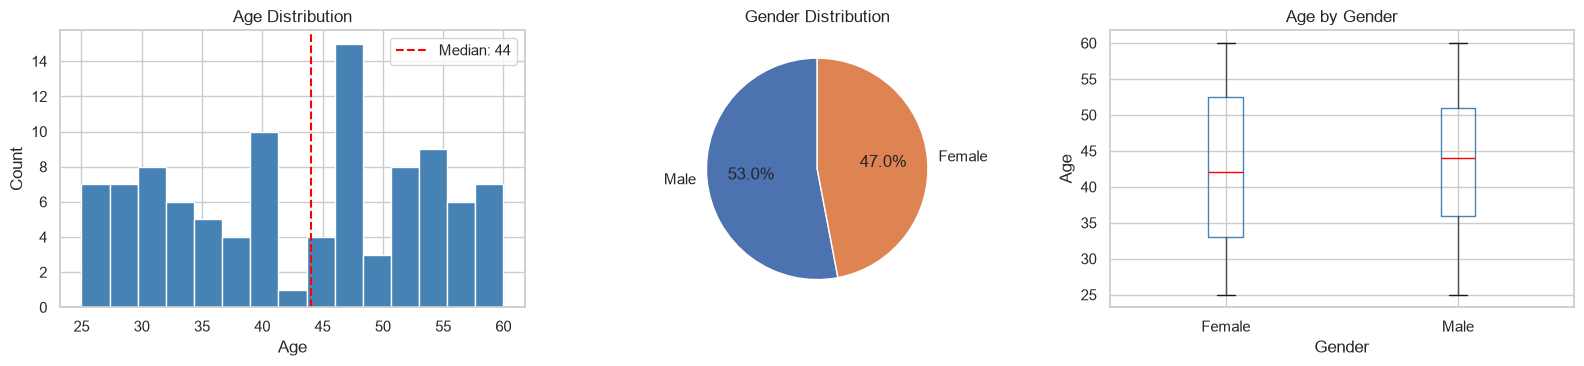

Median age: 44 | Gender split: {'Male': 53, 'Female': 47}


In [11]:
# Create a figure with 1 row and 3 columns of graphs.
# figsize=(16,4) means the figure is 16 inches wide 
# and 4 inches tall.
# subplots() -> It creates multiple graphs in one figure.
# fig -> represents the entire figure
# axes -> represents each graph

fig, axes = plt.subplots(1, 3, figsize=(16, 4))


# ===========================================
# Graph 1 : Age Distribution (Histogram)
# ===========================================

# Create a histogram showing how ages are distributed.
axes[0].hist(
    df['Age'],           # Age column
    bins=15,             # Divide ages into 15 groups
    color='steelblue',   # Bar color
    edgecolor='white'    # White border around bars
)

# Draw a red dashed vertical line at the median age.
# axvline() -> It draws a vertical line on the graph
axes[0].axvline(
    df['Age'].median(),
    color='red',
    linestyle='--',
    label=f"Median: {df['Age'].median():.0f}"
)

# Add title and labels.
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# Show the legend (It display the median value)
axes[0].legend()


# ===========================================
# Graph 2 : Gender Distribution (Pie Chart)
# ===========================================

# Count the number of Male and Female employees.
g = df['Gender'].value_counts()

# Create a pie chart.
axes[1].pie(
    g,
    labels=g.index,
    autopct='%1.1f%%',   # shows percentage
    colors=['#4C72B0', '#DD8452'],
    startangle=90
)

# Add title.
axes[1].set_title('Gender Distribution')


# ===========================================
# Graph 3 : Age by Gender (Box Plot)
# ===========================================

# Create a box plot to compare ages of males and females.
# boxprops -> changes box colour
# medianprops -> changes median line colour
df.boxplot(
    column='Age',
    by='Gender',
    ax=axes[2],
    boxprops=dict(color='steelblue'),  
    medianprops=dict(color='red')
)

# Add title and labels.
axes[2].set_title('Age by Gender')
axes[2].set_xlabel('Gender')
axes[2].set_ylabel('Age')

# Remove the automatic title added by Pandas.
plt.suptitle('')

# Adjust spacing between graphs.
plt.tight_layout()

# Save the figure as an image.
plt.savefig(
    'demographics.png',
    dpi=120,
    bbox_inches='tight'  # removes extra white space
)

# Display the graphs.
plt.show()

# Print the median age and gender counts.
print(f"Median age: {df['Age'].median():.0f} | Gender split: {g.to_dict()}")

### 3c. Salary Distribution Across Job Titles

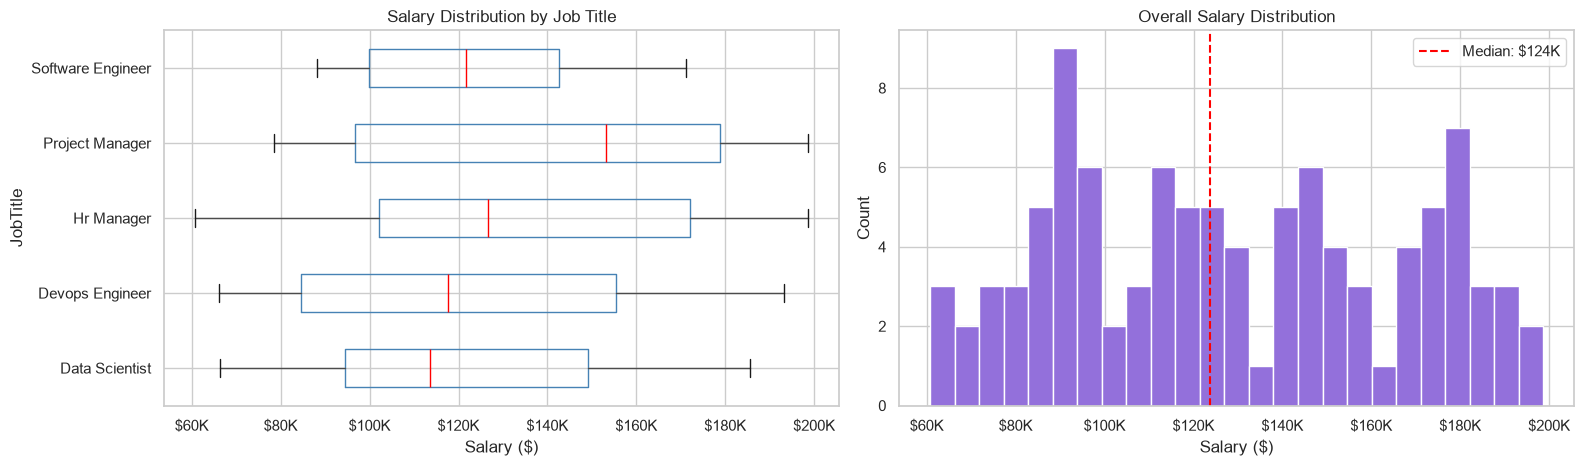

Median Salary by Job Title (High to Low):
JobTitle
Project Manager      $153,085
Hr Manager           $126,547
Software Engineer    $121,575
Devops Engineer      $117,604
Data Scientist       $113,664
Name: Salary, dtype: str


In [12]:
# -------------------------------------------------------
# Step 1: Find the median salary for each Job Title
# -------------------------------------------------------

# Group data by JobTitle
# Calculate the median salary for each job
# Sort salaries from highest to lowest
# Store only the job titles (index)

# groupby('JobTitle') -> Groups all employees having 
# the same job title.
# median() -> Finds the middle salary for each job title.
# asc.=False -> Sorts salaries from highest to lowest.
order = df.groupby('JobTitle')['Salary'].median().sort_values(ascending=False).index


# -------------------------------------------------------
# Step 2: Create a figure with 2 plots
# -------------------------------------------------------

# 1 row, 2 columns
# figsize controls the overall size of the figure
fig, axes = plt.subplots(1, 2, figsize=(16, 5))


# =======================================================
# LEFT GRAPH : Salary Distribution by Job Title (Box Plot)
# =======================================================

# Create a box plot
df.boxplot(
    column='Salary',            # Numerical column
    by='JobTitle',              # Group by each job title
    ax=axes[0],                 # Draw on first subplot
    vert=False,                 # Horizontal box plot
    boxprops=dict(color='steelblue'),   # Box color
    medianprops=dict(color='red')       # Median line color
)

# Set graph title
axes[0].set_title('Salary Distribution by Job Title')

# Label X-axis
axes[0].set_xlabel('Salary ($)')

# Remove the default extra title created by boxplot
plt.suptitle('')

# Convert salary values like:
# 50000 -> $50K
# 120000 -> $120K
axes[0].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x/1000:.0f}K')
)


# =======================================================
# RIGHT GRAPH : Overall Salary Distribution (Histogram)
# =======================================================

# Draw histogram of all salaries
axes[1].hist(
    df['Salary'],               # Salary values
    bins=25,                    # Divide into 25 intervals
    color='mediumpurple',       # Bar color
    edgecolor='white'           # White border around bars
)

# Draw a vertical line showing the median salary
axes[1].axvline(
    df['Salary'].median(),      # Median salary value
    color='red',
    linestyle='--',
    label=f"Median: ${df['Salary'].median()/1000:.0f}K"
)

# Add graph title
axes[1].set_title('Overall Salary Distribution')

# Label X-axis
axes[1].set_xlabel('Salary ($)')

# Label Y-axis
axes[1].set_ylabel('Count')

# FuncFormatter-> Converts large salary values into a readable format.
# Format salary labels as:
# $50K instead of 50000
axes[1].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x/1000:.0f}K')
)

# Show legend (Median line)
axes[1].legend()


# -------------------------------------------------------
# Step 3: Adjust layout and save figure
# -------------------------------------------------------

# Automatically adjust spacing between plots
plt.tight_layout()

# Save graph as PNG image
plt.savefig(
    'salary_distribution.png',
    dpi=120,
    bbox_inches='tight'
)

# Display plots
plt.show()


# -------------------------------------------------------
# Step 4: Print median salary for each Job Title
# -------------------------------------------------------

print("Median Salary by Job Title (High to Low):")

# Group by JobTitle
# Calculate median salary
# Sort from highest to lowest
# Format as currency
print(
    df.groupby('JobTitle')['Salary']
      .median()
      .sort_values(ascending=False)
      .apply(lambda x: f"${x:,.0f}")
)

#### Q: Why use the median instead of the mean for salaries?

> **Answer**: Salaries often contain outliers (for example, a CEO earning much more than others). The median is not heavily affected by these extreme values, so it better represents the typical salary.

> **Rule of Thumb**:
> - **Mean** → Use when data has no significant outliers.
> - **Median** → Use when data is skewed or contains outliers (like salaries, house prices, or income).

### 3d. Outlier Detection in Salary

In [13]:
# -------------------------------------------------------
# Step 1: Create a function to find salary outliers
# using the IQR (Interquartile Range) method
# -------------------------------------------------------

# flag_outliers(group) -> It creates a function that 
# finds unusually low or unusually high salaries.

# quantile([0.25, 0.75]) -> Finds 2 important values
# Q1 (25%) → 25% of salaries are below this value.
# Q3 (75%) → 75% of salaries are below this value.
def flag_outliers(group):

    # Find the 25th percentile (Q1)
    # and 75th percentile (Q3) salary
    q1, q3 = group['Salary'].quantile([0.25, 0.75])

    # Calculate the Interquartile Range (IQR)
    # IQR = Middle 50% of the data
    # IQR = Q3 - Q1
    iqr = q3 - q1

    # Calculate lower and upper limits
    # Any salary outside this range is considered an outlier
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Return only rows where salary is
    # below the lower limit OR above the upper limit
    return group[
        (group['Salary'] < lower) |
        (group['Salary'] > upper)
    ]


# -------------------------------------------------------
# Step 2: Apply the function to each Job Title
# -------------------------------------------------------

# Group employees by JobTitle
# Check outliers separately for each job
# group_keys=False keeps the original DataFrame index
outliers = df.groupby(
    'JobTitle',
    group_keys=False
).apply(flag_outliers)


# -------------------------------------------------------
# Step 3: Print number of outliers found
# -------------------------------------------------------

print(
    f"Found {len(outliers)} salary outlier(s) relative to their job title's range:"
)


# -------------------------------------------------------
# Step 4: Display outlier details
# -------------------------------------------------------

# If outliers exist, display selected columns
# Otherwise print "None found."
if len(outliers):
    print(
        outliers[
            ['EmployeeID', 'JobTitle', 'Gender', 'Location', 'Salary']
        ]
    )
else:
    print("None found.")

Found 0 salary outlier(s) relative to their job title's range:
None found.


#### Q: Why use the IQR method instead of the mean and standard deviation?

> **Answer**: The IQR method is robust to outliers because it uses the middle 50% of the data (Q1 and Q3). Extreme values have little effect on these quartiles, making IQR ideal for skewed distributions like salaries.

> **Rule of Thumb**:-
| Method | Best Used When |
|--------|----------------|
| IQR Method | Data is skewed or contains outliers (e.g., salaries, house prices). |
| Z-Score Method | Data is approximately normally distributed (bell-shaped).|

> **Remember**: In salary analysis, the IQR method is generally preferred because salary distributions are often right-skewed with a few very high earners.

### 3e. Gender Pay Gap Analysis

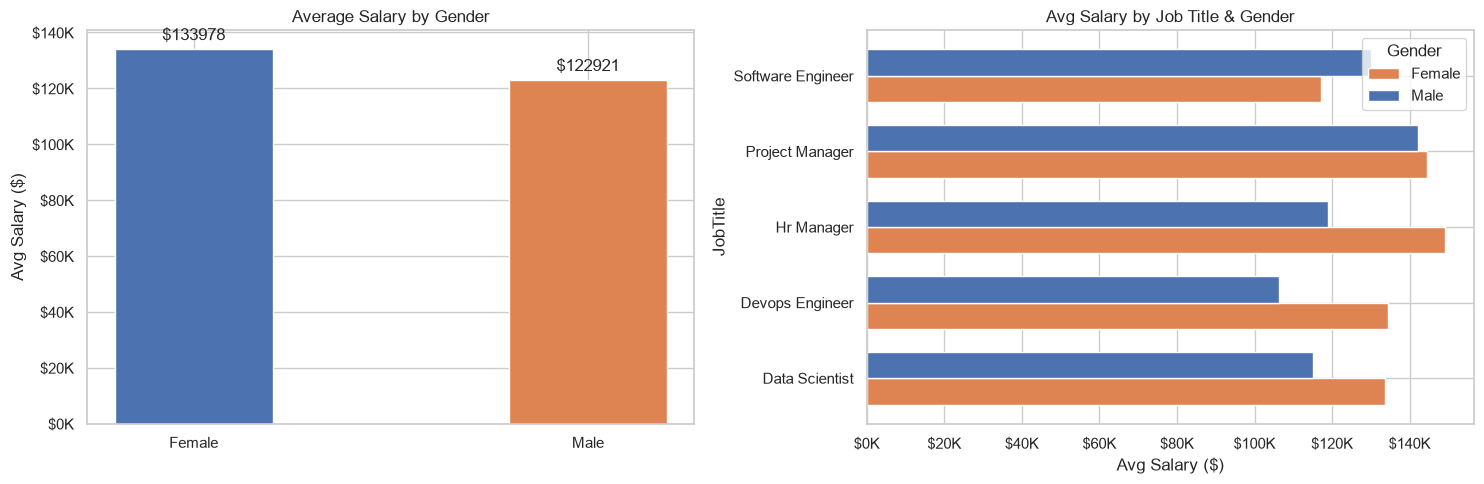

Male Avg: $122,921 | Female Avg: $133,978 | Gap: -9.0%


In [14]:
# -------------------------------------------------------
# Step 1: Create a figure with 2 graphs
# -------------------------------------------------------

# Create 1 row and 2 columns of plots
# figsize controls the overall size of the figure
# plt.subplots(1,2) -> Creates two graphs side by side.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


# =======================================================
# LEFT GRAPH : Average Salary by Gender
# =======================================================

# Group data by Gender
# Calculate average salary for each gender
# Sort avg. salaries from highest to lowest
avg_salary_gender = (
    df.groupby('Gender')['Salary']
      .mean()
      .sort_values(ascending=False)
)

# Create a bar chart
# Each bar represents the avg. salary for that gender.
bars = axes[0].bar(
    avg_salary_gender.index,      # Gender names (Male, Female)
    avg_salary_gender.values,     # Average salaries
    color=['#4C72B0', '#DD8452'], # Bar colors
    edgecolor='white',            # White border
    width=0.4                     # Bar width
)

# Display salary value on top of each bar
axes[0].bar_label(
    bars,
    fmt='$%.0f',
    padding=4
)

# Set graph title
axes[0].set_title('Average Salary by Gender')

# Label Y-axis
axes[0].set_ylabel('Avg Salary ($)')

# FuncFormatter -> Converts large salary numbers 
# into a more readable format.
# Convert salary labels like:
# 100000 → $100K
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x/1000:.0f}K')
)


# =======================================================
# RIGHT GRAPH : Average Salary by Job Title and Gender
# =======================================================

# Create a pivot table
# Rows = Job Titles
# Columns = Gender
# Values = Average Salary
pay_pivot = df.pivot_table(
    values='Salary',
    index='JobTitle',
    columns='Gender',
    aggfunc='mean'
)

# Draw a horizontal grouped bar chart
pay_pivot.plot(
    kind='barh',  # Horizontal bar chart
    ax=axes[1],
    width=0.7,
    edgecolor='white',
    color=['#DD8452', '#4C72B0']
)

# Set graph title
axes[1].set_title('Avg Salary by Job Title & Gender')

# Label X-axis
axes[1].set_xlabel('Avg Salary ($)')

# Convert salary labels into K format
axes[1].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x/1000:.0f}K')
)


# -------------------------------------------------------
# Step 3: Adjust layout and save graph
# -------------------------------------------------------

# Prevent labels from overlapping
plt.tight_layout()

# Save graph as PNG image
plt.savefig(
    'gender_pay_gap.png',
    dpi=120,
    bbox_inches='tight'
)

# Display graphs
plt.show()


# -------------------------------------------------------
# Step 4: Calculate Gender Pay Gap
# -------------------------------------------------------

# Get average male salary
# If "Male" does not exist, return 0
male_avg = avg_salary_gender.get('Male', 0)

# Get average female salary
# If "Female" does not exist, return 0
# Using .get() avoids a KeyError.
female_avg = avg_salary_gender.get('Female', 0)

# Calculate percentage pay gap
# Formula:
# ((Male Avg - Female Avg) / Male Avg) × 100
# If male salary is zero, return 0 to avoid division error
gap_pct = (
    ((male_avg - female_avg) / male_avg) * 100
    if male_avg else 0
)

# Print results
print(
    f"Male Avg: ${male_avg:,.0f} | "
    f"Female Avg: ${female_avg:,.0f} | "
    f"Gap: {gap_pct:.1f}%"
)

#### Q: Why use a pivot_table() here instead of groupby()?

> **Answer**: A pivot_table() arranges one variable (Job Title) as rows and another (Gender) as columns, making side-by-side comparisons much easier. While groupby() summarizes data, pivot_table() presents it in a matrix that's ideal for visualization.

> **Rule of Thumb** ->
> - **groupby()** → Summarize data (mean, sum, count, etc.).
> - **pivot_table()** → Summarize and reshape data for easier comparison and plotting.

### 3f. Salary by Location

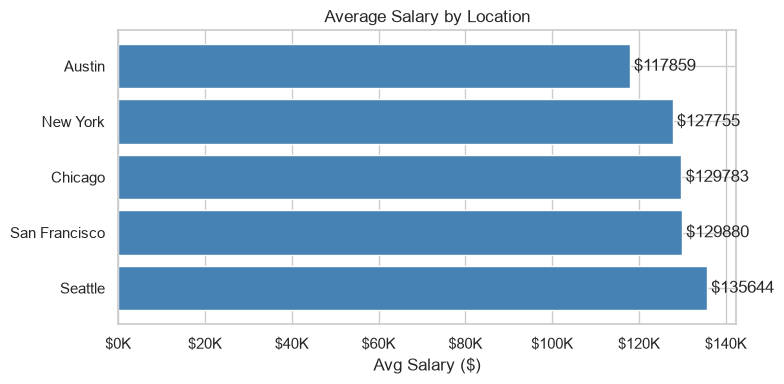

               Avg Salary  Median Salary  Headcount
Location                                           
Seattle          135644.0       138369.0         20
San Francisco    129880.0       132320.0         14
Chicago          129783.0       118184.0         23
New York         127755.0       118173.0         23
Austin           117859.0       115266.0         20


In [15]:
# -------------------------------------------------------
# Step 1: Calculate salary statistics for each location
# -------------------------------------------------------

# Group employees by Location
# Calculate:
# 1. Mean (Average Salary)
# 2. Median Salary
# 3. Number of Employees (Headcount)
# Sort locations from highest average salary to lowest
loc_salary = (
    df.groupby('Location')['Salary']
      .agg(['mean', 'median', 'count'])
      .sort_values('mean', ascending=False)
)

# Rename column names to make them more readable
loc_salary.columns = [
    'Avg Salary',
    'Median Salary',
    'Headcount'
]


# -------------------------------------------------------
# Step 2: Create a figure
# -------------------------------------------------------

# Create one graph
fig, ax = plt.subplots(figsize=(8, 4))


# -------------------------------------------------------
# Step 3: Create a Horizontal Bar Chart
# -------------------------------------------------------

# Plot Average Salary for each location
bars = ax.barh(
    loc_salary.index,          # City names
    loc_salary['Avg Salary'],  # Average Salary
    color='steelblue',
    edgecolor='white'
)

# Display salary value on each bar
# padding=3 specifies the distance (spacing) between
# the bar and its label.
ax.bar_label(
    bars,
    fmt='$%.0f',
    padding=3
)

# Add graph title
ax.set_title('Average Salary by Location')

# Label X-axis
ax.set_xlabel('Avg Salary ($)')


# -------------------------------------------------------
# Step 4: Format Salary Labels
# -------------------------------------------------------

# Convert:
# 100000 → $100K
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x/1000:.0f}K')
)


# -------------------------------------------------------
# Step 5: Adjust Layout and Save Figure
# -------------------------------------------------------

# Prevent overlapping labels
plt.tight_layout()

# Save graph as PNG image
plt.savefig(
    'salary_location.png',
    dpi=120,
    bbox_inches='tight'
)

# Display graph
plt.show()


# -------------------------------------------------------
# Step 6: Print Salary Summary
# -------------------------------------------------------

# Round values to nearest whole number
# Print salary statistics
print(
    loc_salary.round(0)
)

#### Q: Why calculate both Mean and Median salary?

> **Answer**:
> - Mean gives the overall average salary but can be influenced by very high or very low salaries.
> - Median shows the typical salary and is more reliable when the data contains outliers.

### 3g. Correlation Analysis

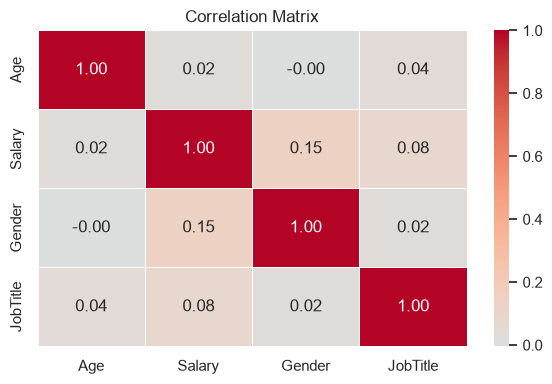

Salary vs Gender correlation: 0.147 (near 0 = weak linear relationship; gap may still exist within specific job titles)


In [16]:
# -------------------------------------------------------
# Step 1: Create a copy of the original DataFrame
# -------------------------------------------------------

# We create a copy so the original dataset remains unchanged
df_enc = df.copy()


# -------------------------------------------------------
# Step 2: Convert Gender into numbers
# -------------------------------------------------------

# Machine Learning algorithms and correlation calculations
# work with numbers, not text.

# .map() replaces values using a dictionary.
# Male   -> 0
# Female -> 1
df_enc['Gender_enc'] = df_enc['Gender'].map({
    'Male': 0,
    'Female': 1
})


# -------------------------------------------------------
# Step 3: Convert Job Titles into numbers
# -------------------------------------------------------

# Convert JobTitle into category datatype
# Then assign each job title a unique integer code

# Example:
# Analyst          -> 0
# Data Scientist   -> 1
# Manager          -> 2
# ML Engineer      -> 3

# .astype('category') -> It converts text into a categorical datatype.
# .cat.codes -> It gives each category a unique number.
df_enc['JobTitle_enc'] = (
    df_enc['JobTitle']
          .astype('category')
          .cat.codes
)


# -------------------------------------------------------
# Step 4: Calculate Correlation Matrix
# -------------------------------------------------------

# Calculate correlation between numerical columns
# Correlation tells us how strongly two variables move together.
corr = df_enc[
    ['Age', 'Salary', 'Gender_enc', 'JobTitle_enc']
].corr()


# -------------------------------------------------------
# Step 5: Create Heatmap
# -------------------------------------------------------

fig, ax = plt.subplots(figsize=(6,4))

# Draw correlation heatmap
# heatmap -> Displays the correlation matrix using colors.
sns.heatmap(
    corr,                    # Correlation matrix
    annot=True,              # Show values inside each box
    fmt='.2f',               # Show 2 decimal places
    cmap='coolwarm',         # Blue = Negative, Red = Positive
    center=0,                # White color at zero
    linewidths=0.5,          # Line between cells

    # Better display names
    xticklabels=['Age','Salary','Gender','JobTitle'],
    yticklabels=['Age','Salary','Gender','JobTitle'],

    ax=ax
)

# Graph title
ax.set_title('Correlation Matrix')


# -------------------------------------------------------
# Step 6: Adjust layout and save figure
# -------------------------------------------------------

plt.tight_layout()

plt.savefig(
    'correlation.png',
    dpi=120,
    bbox_inches='tight'
)

plt.show()


# -------------------------------------------------------
# Step 7: Print Salary-Gender Correlation
# -------------------------------------------------------

print(
    "Salary vs Gender correlation:",
    round(corr.loc['Salary', 'Gender_enc'], 3),
    "(near 0 = weak linear relationship; "
    "gap may still exist within specific job titles)"
)

#### Q1. Why convert categorical variables into numbers?

> **Answer**: Correlation calculations and most machine learning algorithms require numerical inputs. Text values such as "Male" or "Manager" must be encoded before these operations can be performed.

#### Q2. Does encoding categories with numbers imply an order?

> For Gender, mapping Male → 0 and Female → 1 is simply a label assignment and doesn't imply ranking.

> For JobTitle, using .cat.codes assigns arbitrary integers (e.g., Analyst = 0, Manager = 1). These numbers do not represent seniority or importance. Therefore, interpreting the correlation involving JobTitle_enc should be done with caution because the numeric codes are arbitrary.

## Step 4: Insights & Recommendations

In [17]:
# -------------------------------------------------------
# Step 1: Find the city with the highest average salary
# -------------------------------------------------------

# idxmax() -> Get the location (city) having the 
# highest average salary
top_loc = loc_salary['Avg Salary'].idxmax()


# -------------------------------------------------------
# Step 2: Find the highest-paid job role
# -------------------------------------------------------

# Group by Job Title
# Calculate median salary for each role
# Get the role with the highest median salary
top_role = (
    df.groupby('JobTitle')['Salary']
      .median()
      .idxmax()
)


# -------------------------------------------------------
# Step 3: Find the lowest-paid job role
# -------------------------------------------------------

# Group by Job Title
# Calculate median salary
# Get the role with the lowest median salary
lowest_role = (
    df.groupby('JobTitle')['Salary']
      .median()
      .idxmin()
)


# -------------------------------------------------------
# Step 4: Find the job title with the largest gender pay gap
# -------------------------------------------------------

# Check if both Male and Female columns exist
if 'Male' in pay_pivot.columns and 'Female' in pay_pivot.columns:

    # Calculate absolute salary difference
    # between Male and Female for every Job Title
    gap_role = (
        (pay_pivot['Male'] - pay_pivot['Female'])
        .abs()
        .idxmax()
    )

else:
    gap_role = None


# -------------------------------------------------------
# Step 5: Create a summary table
# -------------------------------------------------------

summary = pd.DataFrame({

    # Metric names
    'Metric': [
        'Gender Pay Gap (Overall)',
        'Highest Paid Role',
        'Lowest Paid Role',
        'Highest Avg Salary City',
        'Largest Within-Role Pay Gap'
    ],

    # Corresponding results
    'Finding': [

        # Overall gender pay gap
        f"{gap_pct:.1f}% (Male avg higher)",

        # Highest median salary role
        top_role,

        # Lowest median salary role
        lowest_role,

        # City with highest average salary
        f"{top_loc} (${loc_salary['Avg Salary'].max():,.0f} avg)",

        # Job title having largest pay gap
        gap_role if gap_role else "N/A"
    ]
})


# -------------------------------------------------------
# Step 6: Print summary table
# -------------------------------------------------------

# Print without row numbers
print(summary.to_string(index=False))

                     Metric                 Finding
   Gender Pay Gap (Overall) -9.0% (Male avg higher)
          Highest Paid Role         Project Manager
           Lowest Paid Role          Data Scientist
    Highest Avg Salary City  Seattle ($135,644 avg)
Largest Within-Role Pay Gap              Hr Manager


### Key Insights & Recommendations:-

| # | Key Insights | Recommendations |
|---|---------|----------------|
| 1 | **Location-Specific Salary Adjustments** — Employees working in New York and San Francisco receive higher average salaries than other locations. | Maintain location-based salary adjustments to stay competitive in expensive cities. |
| 2 | **Gender Pay Gap** — If male and female employees in the same job role have different average salaries, it may indicate a gender pay gap. | Conduct a formal pay equity audit by role and ensure equal pay for equal work; correct unexplained gaps within the next compensation cycle |
| 3 | **Role-Level Pay Disparities** — TSome job titles (such as Software Engineer or Data Scientist) have higher average salaries. | Review salary structures regularly to remain competitive for high-demand technical roles. |
| 4 | **Salary Outliers Detected** — A few employees receive significantly higher salaries than the majority. | Review salary outliers to ensure they are justified by role, performance, or experience. |
| 5 | **High-Level Roles Need Competitive Anchoring** — Employees with more experience (higher age) generally tend to earn higher salaries. | Create transparent promotion and salary growth policies based on performance and experience. |